# Mission 3 — Segmentation clients (K-Means)
**TP Customer Intelligence & AI Marketing Strategy — cas NovaMarket**

**Objectif :** regrouper les clients en segments homogènes et actionnables, les décrire, les nommer et proposer une action différenciée pour chacun.

**Plan**

0. Mise en place
1. Chargement de la table préparée (mission 2)
2. Choix des variables
3. Standardisation
4. Test de K-Means pour k = 2 à 8
5. Choix du nombre de segments
6. Segmentation finale et nommage
7. Profil des segments
8. Actions différenciées par segment
9. Stabilité et limites
10. Export de `customer_segments.csv`

## 0. Mise en place

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_NovaMarket'
except ImportError:
    BASE = os.environ.get('TP_BASE', '..')

DATA = os.path.join(BASE, 'data')
OUT = os.path.join(BASE, 'outputs')
os.makedirs(OUT, exist_ok=True)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

COULEURS = {'Fidèles premium': '#2E7D32', 'Réguliers satisfaits': '#1565C0',
            'Occasionnels récents': '#F9A825', 'En décrochage': '#C62828',
            'Nouveaux à activer': '#7B1FA2'}

## 1. Chargement de la table préparée
On repart de `customers_prepared.csv`, produit en mission 2.

Comme décidé lors de l'audit, les **80 clients sans commande** sont **mis de côté** pour le K-Means. Ils ont 0 commande et un CA nul : ils formeraient un groupe artificiel et déplaceraient les centres des autres segments. Ils deviennent un segment à part, **« Nouveaux à activer »**.

In [2]:
clients = pd.read_csv(os.path.join(OUT, 'customers_prepared.csv'))
actifs = clients[clients['sans_commande'] == 0].copy()
nouveaux = clients[clients['sans_commande'] == 1].copy()
print(f'Clients au total : {len(clients)}')
print(f'Clients actifs (segmentés par K-Means) : {len(actifs)}')
print(f'Nouveaux clients sans commande (segment à part) : {len(nouveaux)}')

Clients au total : 1500
Clients actifs (segmentés par K-Means) : 1420
Nouveaux clients sans commande (segment à part) : 80


## 2. Choix des variables
On retient les 5 dimensions demandées par l'énoncé, qui décrivent la **valeur** et l'**engagement** du client :

| Dimension | Variable utilisée | Pourquoi cette version |
|---|---|---|
| Récence | `log_days_since_last_order` | Très asymétrique : le log réduit le poids des valeurs extrêmes |
| Fréquence | `orders_12m` | Peu asymétrique, gardée telle quelle |
| Montant | `log_revenue_12m_eur` | Très asymétrique (quelques clients à plus de 3 000 €) |
| Engagement digital | `log_sessions_90d` | Asymétrique |
| Satisfaction | `satisfaction_score` | Déjà sur une échelle de 1 à 5 |

**Variables écartées :**
- `avg_order_value_eur` : le CA vaut déjà commandes × panier moyen, l'ajouter compterait deux fois la même information ;
- `churn_90d` : c'est la **cible** de la mission 4, on ne s'en sert que pour **décrire** les segments après coup ;
- `age`, `region`, `acquisition_channel` : variables descriptives, utilisées seulement pour décrire les segments.

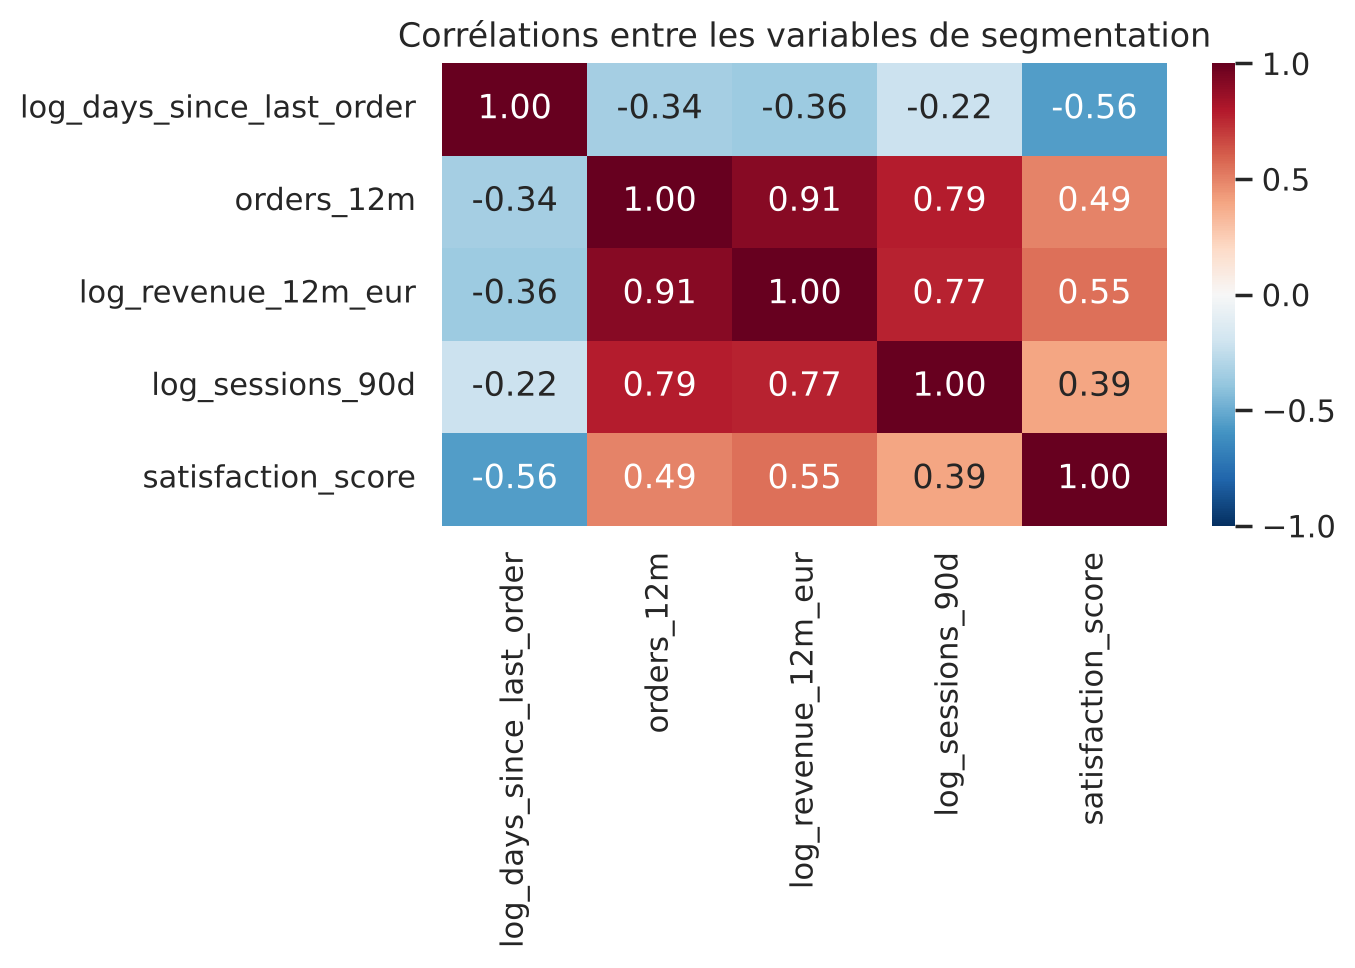

In [3]:
VARIABLES = ['log_days_since_last_order', 'orders_12m', 'log_revenue_12m_eur',
             'log_sessions_90d', 'satisfaction_score']

plt.figure(figsize=(7, 5))
sns.heatmap(actifs[VARIABLES].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Corrélations entre les variables de segmentation')
plt.tight_layout(); plt.show()

**Lecture :** les variables sont liées entre elles sans être redondantes. Une corrélation au-dessus de 0,9 aurait posé problème. Par exemple, les clients satisfaits commandent plus souvent et sont plus récents.

La fréquence et le CA sont les plus proches, ce qui est logique. On garde les deux, car un client peut commander souvent avec de petits paniers.

## 3. Standardisation
K-Means mesure des **distances**. Sans standardisation, une variable mesurée en centaines (sessions) écraserait une variable de 1 à 5 (satisfaction). On ramène chaque variable à une moyenne de 0 et un écart-type de 1.

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(actifs[VARIABLES])

avant = actifs[VARIABLES].agg(['mean', 'std']).T.round(2)
apres = pd.DataFrame(X, columns=VARIABLES).agg(['mean', 'std']).T.round(2)
pd.concat({'avant': avant, 'après standardisation': apres}, axis=1)

avant       après standardisation     
                           mean   std                  mean  std
log_days_since_last_order  3.89  1.00                  -0.0  1.0
orders_12m                 4.80  3.46                   0.0  1.0
log_revenue_12m_eur        5.70  1.03                  -0.0  1.0
log_sessions_90d           3.60  0.62                  -0.0  1.0
satisfaction_score         3.77  0.86                   0.0  1.0

## 4. Test de K-Means pour k = 2 à 8
Trois indicateurs pour chaque valeur de k :
- **Inertie** (méthode du coude) : la dispersion à l'intérieur des segments. Elle baisse toujours quand k augmente, on cherche le « coude » où le gain ralentit.
- **Silhouette** (de −1 à 1, plus haut = mieux) : les clients sont-ils proches de leur segment et loin des autres ?
- **Davies-Bouldin** (plus bas = mieux) : les segments sont-ils compacts et bien séparés ?

In [5]:
resultats = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    tailles = np.bincount(km.labels_)
    resultats.append({
        'k': k,
        'inertie': round(km.inertia_),
        'silhouette': round(silhouette_score(X, km.labels_), 3),
        'davies_bouldin': round(davies_bouldin_score(X, km.labels_), 2),
        'plus_petit_segment_%': round(tailles.min() / len(X) * 100, 1),
    })
resultats = pd.DataFrame(resultats).set_index('k')
resultats

,inertie,silhouette,davies_bouldin,plus_petit_segment_%
k,,,,
2,4019,0.360,1.04,38.7
3,2997,0.316,1.11,20.8
4,2197,0.351,1.00,16.6
5,1948,0.281,1.19,13.4
6,1728,0.283,1.16,11.2
7,1554,0.273,1.20,9.2
8,1454,0.254,1.26,8.5


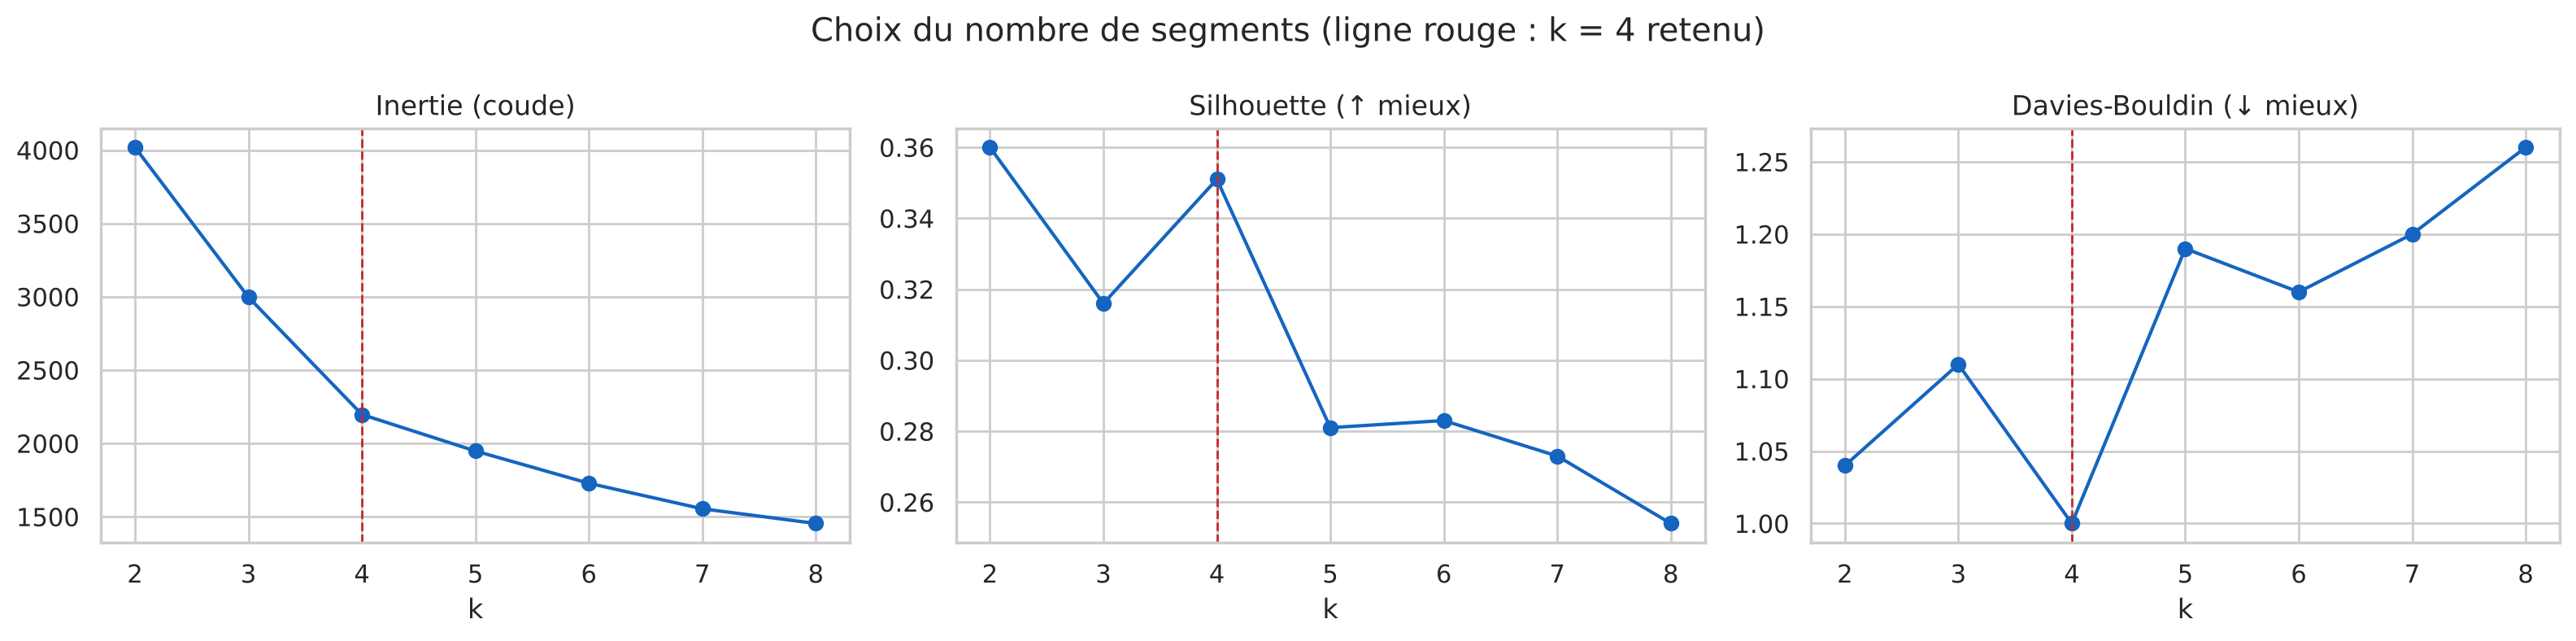

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, titre in zip(axes, ['inertie', 'silhouette', 'davies_bouldin'],
                          ['Inertie (coude)', 'Silhouette (↑ mieux)', 'Davies-Bouldin (↓ mieux)']):
    ax.plot(resultats.index, resultats[col], marker='o', color='#1565C0')
    ax.axvline(4, color='#C62828', ls='--', lw=1)
    ax.set_title(titre); ax.set_xlabel('k')
plt.suptitle('Choix du nombre de segments (ligne rouge : k = 4 retenu)')
plt.tight_layout(); plt.show()

## 5. Choix du nombre de segments : k = 4
- **k = 2** a la meilleure silhouette, mais ne sépare que les clients « actifs » des clients « à risque ». C'est trop grossier pour personnaliser des actions.
- **k = 4** est le meilleur compromis :
    - c'est la **2ᵉ meilleure silhouette** (≈ 0,35, nettement au-dessus de k = 3 et de k ≥ 5) ;
    - c'est le **meilleur Davies-Bouldin** (≈ 1,00) ;
    - c'est le **coude** de la courbe d'inertie : au-delà, chaque segment en plus apporte peu ;
    - **tous les segments pèsent plus de 15 % de la base**, donc chacun justifie une campagne dédiée.
- À partir de **k = 5**, les indicateurs se dégradent et des segments proches se dédoublent sans changer l'action marketing.

**Avec le segment « Nouveaux à activer », NovaMarket dispose donc de 5 segments.**

## 6. Segmentation finale et nommage
Les numéros de cluster de K-Means sont **arbitraires** et peuvent changer d'une version de scikit-learn à l'autre. On nomme donc les segments par des **règles métier**, pas par leur numéro :
- le segment au **churn le plus élevé** → *En décrochage* ;
- le segment au **CA moyen le plus élevé** → *Fidèles premium* ;
- parmi les deux restants, le plus **fréquent** → *Réguliers satisfaits*, l'autre → *Occasionnels récents*.

In [7]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
actifs['cluster_kmeans'] = kmeans.labels_

moy = actifs.groupby('cluster_kmeans')[['churn_90d', 'revenue_12m_eur', 'orders_12m']].mean()
c_risque = moy['churn_90d'].idxmax()
c_premium = moy.drop(c_risque)['revenue_12m_eur'].idxmax()
restants = moy.drop([c_risque, c_premium])
c_reguliers = restants['orders_12m'].idxmax()
c_occasionnels = restants.drop(c_reguliers).index[0]

NOMS = {c_premium: 'Fidèles premium', c_reguliers: 'Réguliers satisfaits',
        c_occasionnels: 'Occasionnels récents', c_risque: 'En décrochage'}
actifs['segment'] = actifs['cluster_kmeans'].map(NOMS)

nouveaux['cluster_kmeans'] = -1
nouveaux['segment'] = 'Nouveaux à activer'

segments = pd.concat([actifs, nouveaux]).sort_values('customer_id')
ORDRE = ['Fidèles premium', 'Réguliers satisfaits', 'Occasionnels récents', 'En décrochage', 'Nouveaux à activer']
segments['segment'].value_counts().reindex(ORDRE).to_frame('clients')

,clients
segment,
Fidèles premium,236
Réguliers satisfaits,516
Occasionnels récents,274
En décrochage,394
Nouveaux à activer,80


## 7. Profil des segments
Taille, valeur, engagement, satisfaction et récence. Le churn est affiché pour **décrire** les segments : il n'a pas servi à les construire.

In [8]:
ca_total = segments['revenue_12m_eur'].sum()
profil = segments.groupby('segment').agg(
    clients=('customer_id', 'size'),
    recence_jours=('days_since_last_order', 'mean'),
    commandes_12m=('orders_12m', 'mean'),
    CA_moyen_eur=('revenue_12m_eur', 'mean'),
    CA_total_eur=('revenue_12m_eur', 'sum'),
    panier_moyen_eur=('avg_order_value_eur', 'mean'),
    sessions_90j=('sessions_90d', 'mean'),
    satisfaction=('satisfaction_score', 'mean'),
    tickets_support=('support_tickets_90d', 'mean'),
    retours_12m=('returns_12m', 'mean'),
    taux_clic_email=('taux_clic_email', 'mean'),
    nb_categories=('nb_categories', 'mean'),
    taux_churn=('churn_90d', 'mean'),
).reindex(ORDRE)
profil.insert(1, 'part_base_%', profil['clients'] / len(segments) * 100)
profil.insert(6, 'part_CA_%', profil['CA_total_eur'] / ca_total * 100)
profil['taux_churn'] = profil['taux_churn'] * 100
profil = profil.round(1)
profil.to_csv(os.path.join(OUT, 'segment_profiles.csv'))
profil.T

segment,Fidèles premium,Réguliers satisfaits,Occasionnels récents,En décrochage,Nouveaux à activer
clients,236.0,516.0,274.0,394.0,80.0
part_base_%,15.7,34.4,18.3,26.3,5.3
recence_jours,21.5,58.0,27.8,154.3,14.6
commandes_12m,11.1,5.2,1.9,2.5,0.0
CA_moyen_eur,1628.0,443.3,142.6,156.9,0.0
CA_total_eur,384208.7,228726.0,39064.7,61825.1,0.0
part_CA_%,53.8,32.0,5.5,8.7,0.0
panier_moyen_eur,146.3,85.0,73.5,62.8,0.0
sessions_90j,89.4,46.5,20.6,27.0,9.3
satisfaction,4.6,4.1,3.9,2.7,3.8


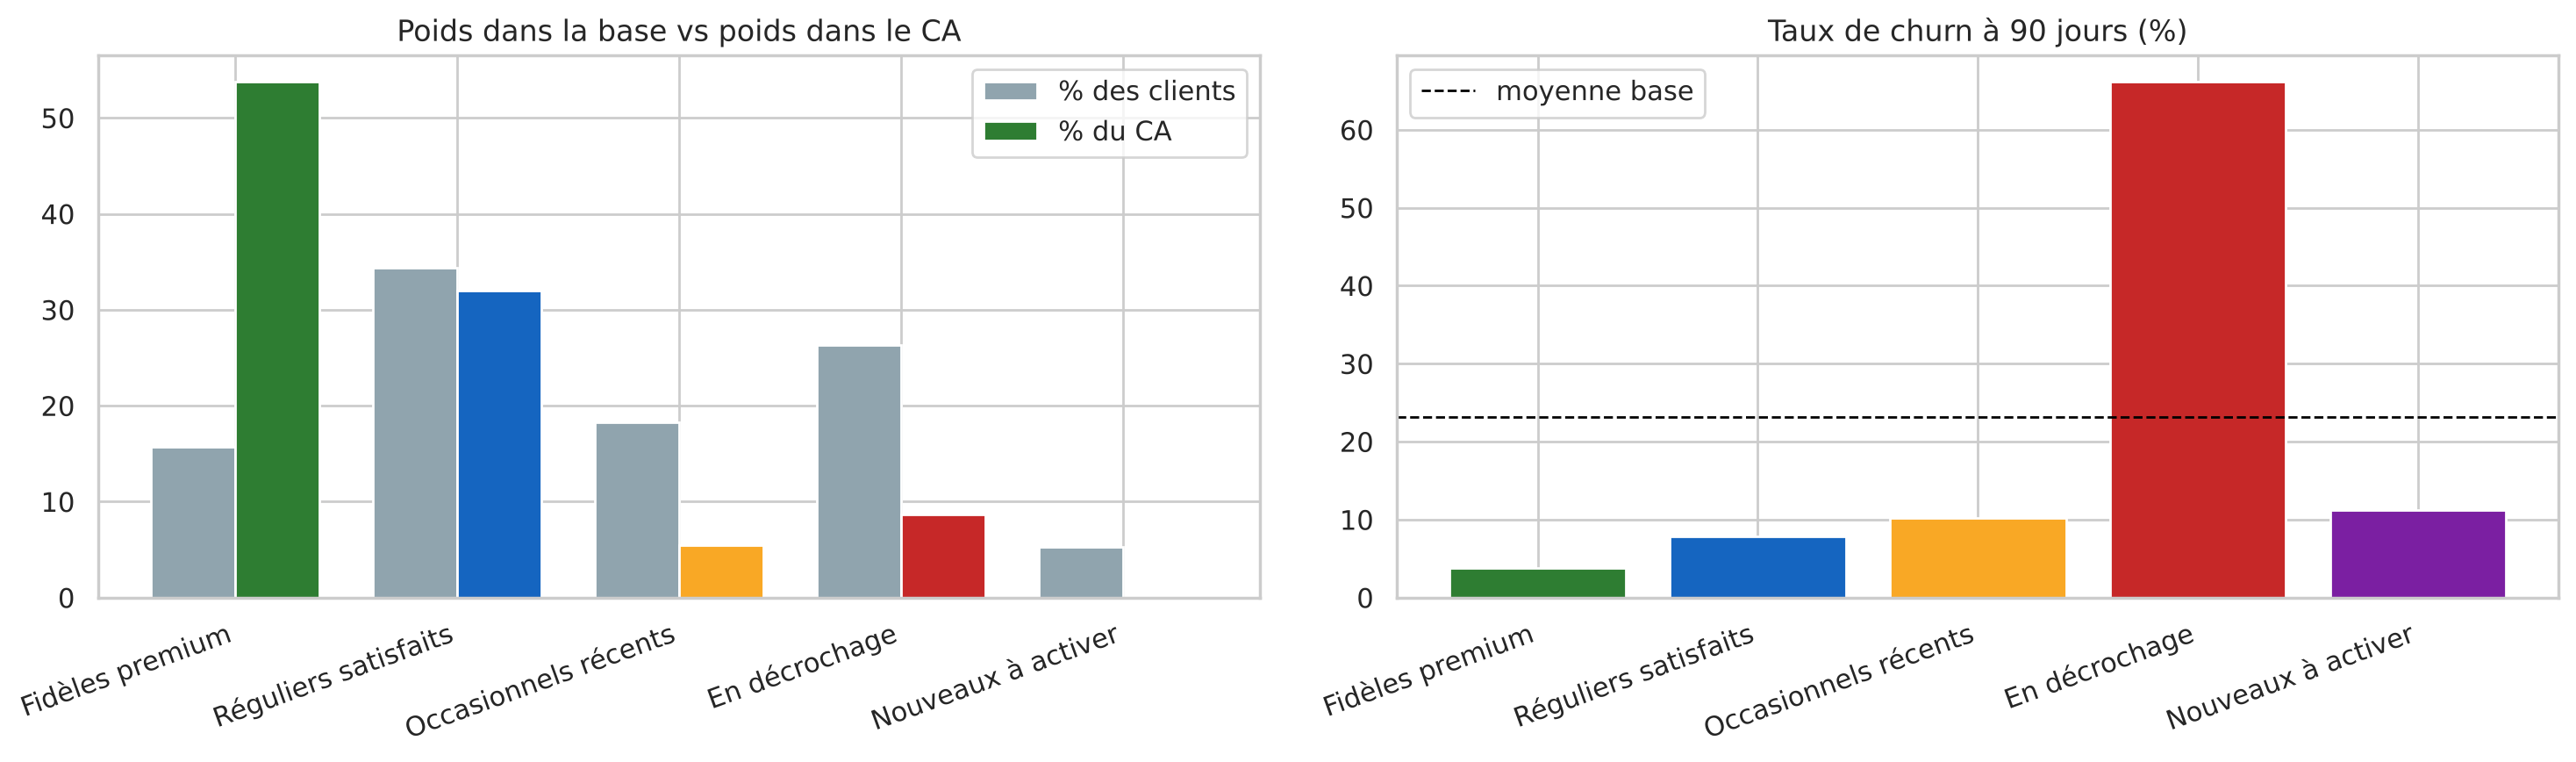

In [9]:
# Poids de chaque segment dans la base et dans le CA
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(ORDRE)); w = 0.38
axes[0].bar(x - w/2, profil['part_base_%'], w, label='% des clients', color='#90A4AE')
axes[0].bar(x + w/2, profil['part_CA_%'], w, label='% du CA', color=[COULEURS[s] for s in ORDRE])
axes[0].set_xticks(x); axes[0].set_xticklabels(ORDRE, rotation=20, ha='right')
axes[0].set_title('Poids dans la base vs poids dans le CA'); axes[0].legend()

axes[1].bar(ORDRE, profil['taux_churn'], color=[COULEURS[s] for s in ORDRE])
axes[1].axhline(segments['churn_90d'].mean() * 100, color='black', ls='--', lw=1, label='moyenne base')
axes[1].set_title('Taux de churn à 90 jours (%)'); axes[1].legend()
axes[1].set_xticks(range(len(ORDRE))); axes[1].set_xticklabels(ORDRE, rotation=20, ha='right')
plt.tight_layout(); plt.show()

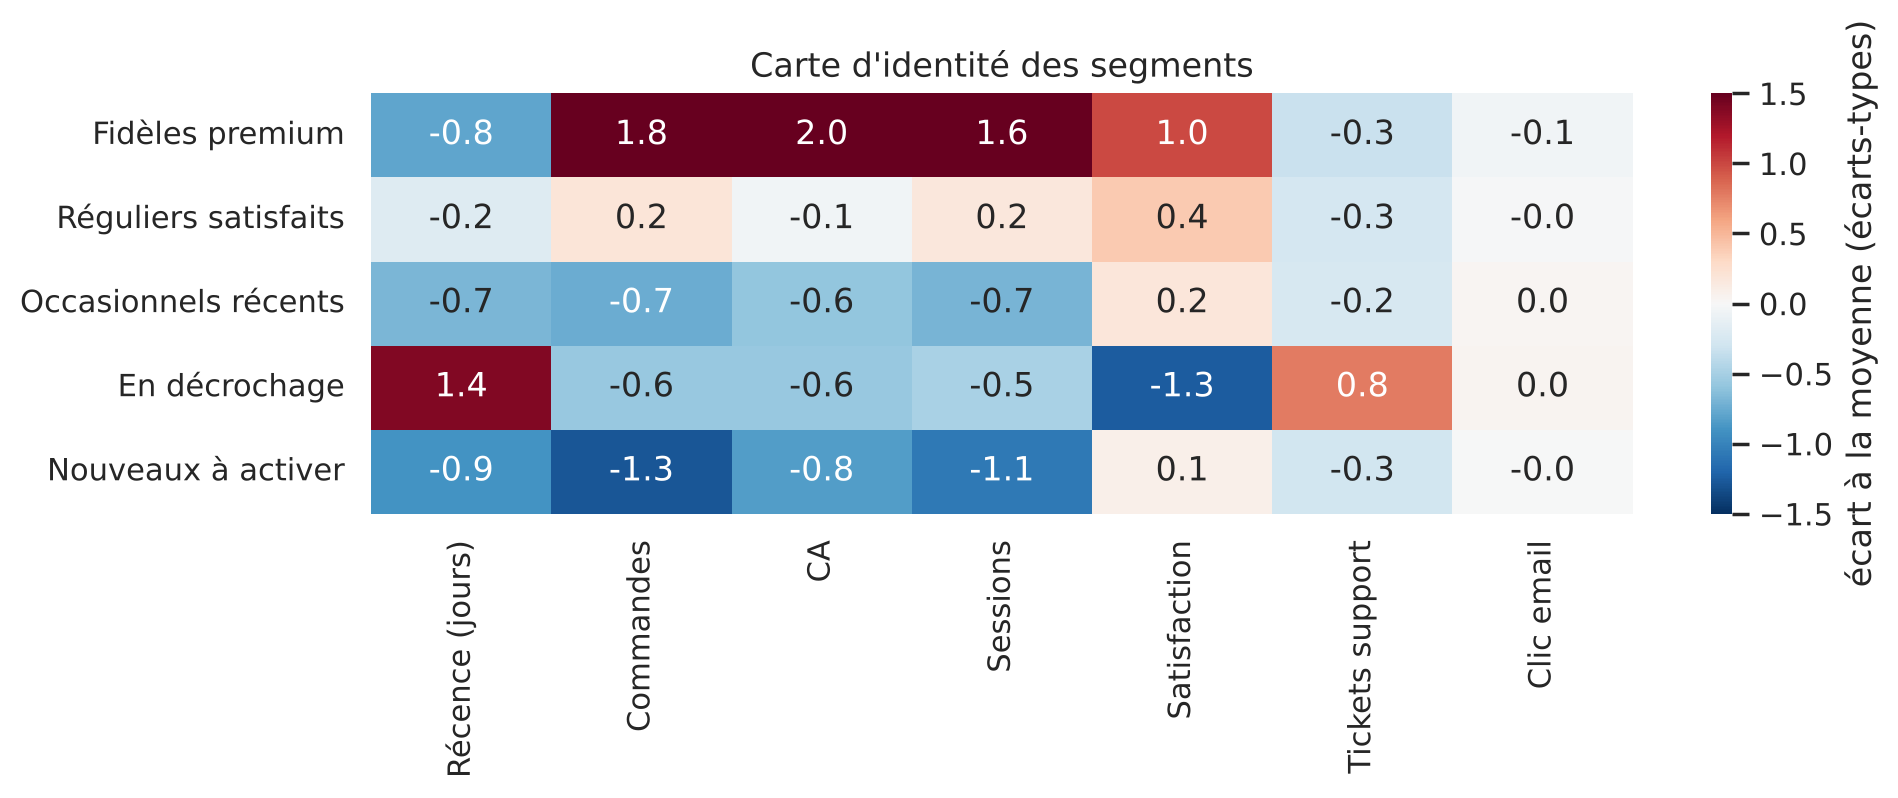

In [10]:
# Carte d'identité : chaque case = écart du segment à la moyenne, en écarts-types
dims = {'Récence (jours)': 'days_since_last_order', 'Commandes': 'orders_12m', 'CA': 'revenue_12m_eur',
        'Sessions': 'sessions_90d', 'Satisfaction': 'satisfaction_score',
        'Tickets support': 'support_tickets_90d', 'Clic email': 'taux_clic_email'}
z = pd.DataFrame({nom: (segments.groupby('segment')[col].mean() - segments[col].mean()) / segments[col].std()
                  for nom, col in dims.items()}).reindex(ORDRE)
plt.figure(figsize=(10, 4))
sns.heatmap(z, annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-1.5, vmax=1.5,
            cbar_kws={'label': 'écart à la moyenne (écarts-types)'})
plt.title("Carte d'identité des segments"); plt.ylabel('')
plt.tight_layout(); plt.show()

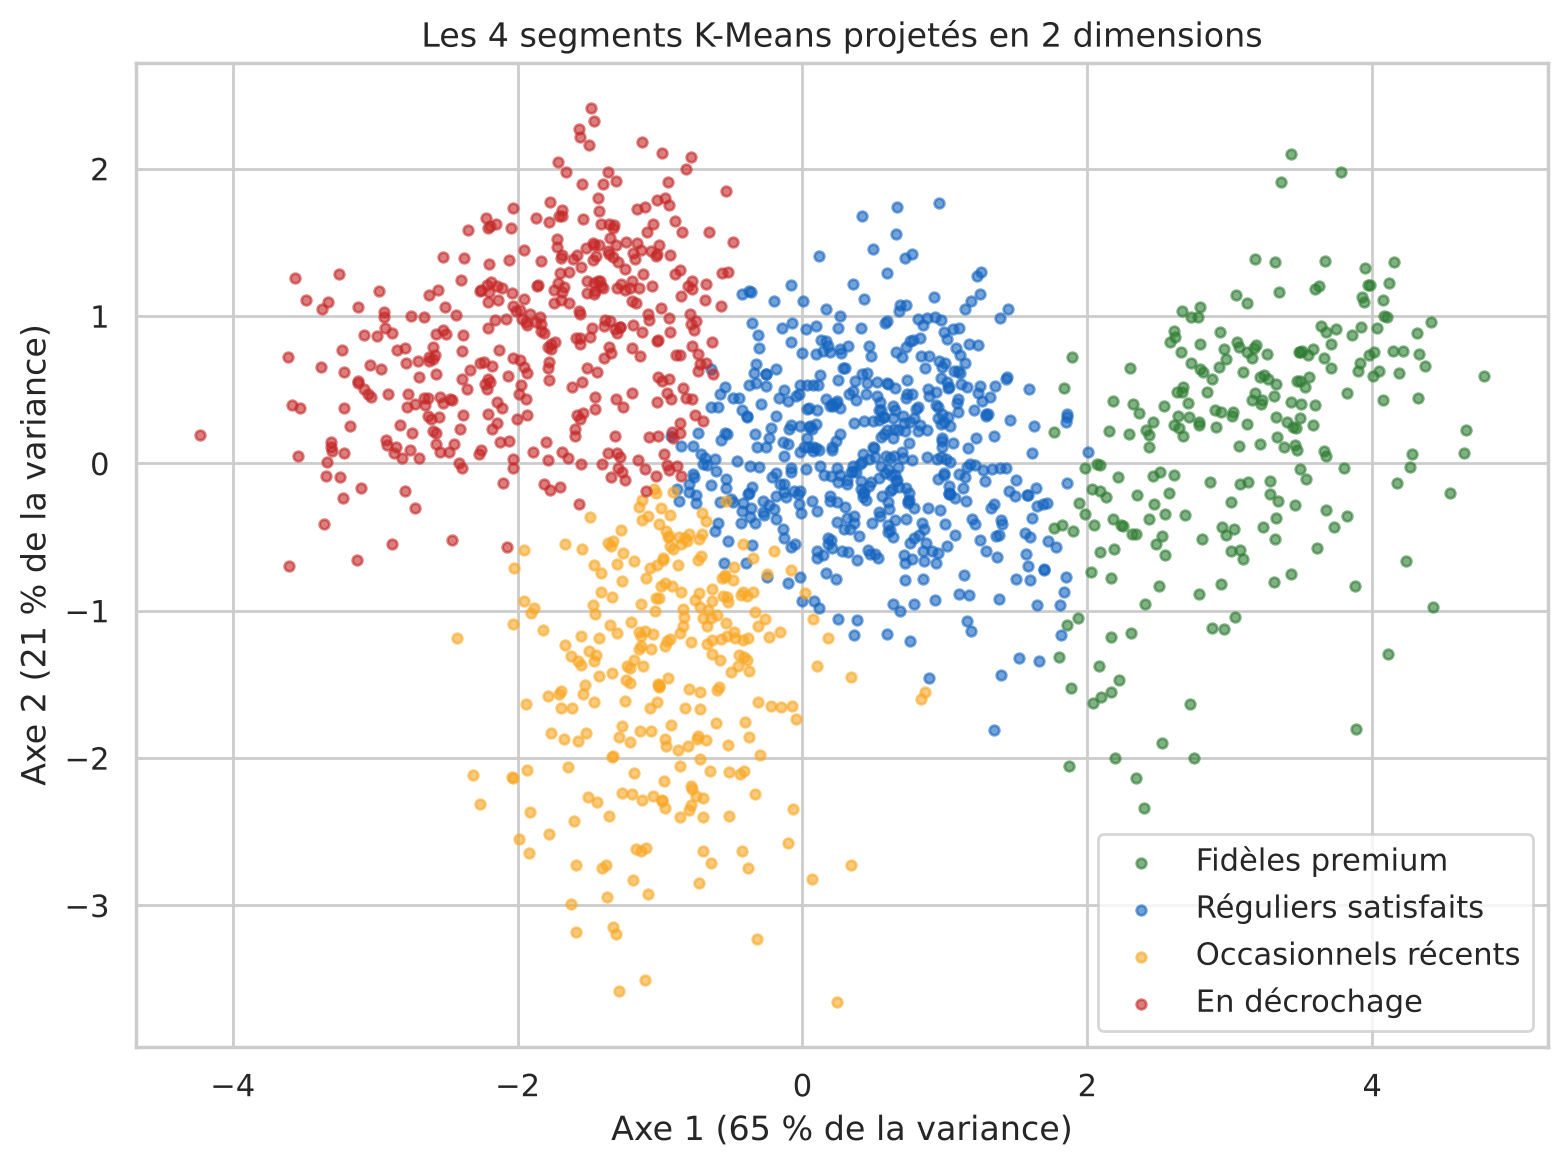

In [11]:
# Projection en 2 dimensions (ACP) pour visualiser la séparation des 4 segments K-Means
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
plt.figure(figsize=(8, 6))
for nom in ORDRE[:4]:
    m = (actifs['segment'] == nom).values
    plt.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, label=nom, color=COULEURS[nom])
plt.xlabel(f'Axe 1 ({pca.explained_variance_ratio_[0]*100:.0f} % de la variance)')
plt.ylabel(f'Axe 2 ({pca.explained_variance_ratio_[1]*100:.0f} % de la variance)')
plt.title('Les 4 segments K-Means projetés en 2 dimensions')
plt.legend(); plt.tight_layout(); plt.show()

In [12]:
# Variables descriptives : catégorie principale et canal d'acquisition par segment (% en ligne)
display((pd.crosstab(segments['segment'], segments['categorie_principale'], normalize='index') * 100).round(0).reindex(ORDRE))
display((pd.crosstab(segments['segment'], segments['acquisition_channel'], normalize='index') * 100).round(0).reindex(ORDRE))

categorie_principale,Accessoire,Aucune,Coffret,Maquillage,Parfum,Soin corps,Soin visage
segment,,,,,,,
Fidèles premium,23.0,0.0,25.0,17.0,13.0,12.0,11.0
Réguliers satisfaits,30.0,0.0,20.0,15.0,13.0,11.0,11.0
Occasionnels récents,31.0,0.0,18.0,14.0,17.0,10.0,11.0
En décrochage,26.0,0.0,19.0,18.0,15.0,10.0,11.0
Nouveaux à activer,0.0,100.0,0.0,0.0,0.0,0.0,0.0


acquisition_channel,Direct,Email,Paid Social,Referral,SEO
segment,,,,,
Fidèles premium,22.0,23.0,24.0,10.0,22.0
Réguliers satisfaits,21.0,21.0,20.0,10.0,29.0
Occasionnels récents,25.0,19.0,18.0,14.0,25.0
En décrochage,23.0,19.0,18.0,14.0,27.0
Nouveaux à activer,21.0,21.0,25.0,19.0,14.0


**Lecture des profils** (valeurs arrondies, voir le tableau ci-dessus) :

- **Fidèles premium**
    - 16 % des clients, mais **54 % du CA**.
    - Environ 11 commandes par an, plus de 1 600 € de CA moyen et un panier d'environ 146 €.
    - Satisfaction la plus haute (4,6) et churn quasi nul (4 %).
- **Réguliers satisfaits**
    - Le plus gros segment : 34 % des clients, 32 % du CA.
    - Environ 5 commandes par an, dernière commande il y a environ 2 mois.
    - Satisfaits (4,1), churn faible (8 %).
- **Occasionnels récents**
    - 18 % des clients, mais seulement 5 % du CA.
    - Environ 2 commandes et peu de sessions, mais un achat récent (environ 1 mois) et une bonne satisfaction (3,9).
    - **Potentiel de réachat** à saisir.
- **En décrochage**
    - 26 % des clients, 9 % du CA.
    - Dernière commande il y a environ **5 mois**, satisfaction la plus basse (2,7), presque 2 tickets support en 90 jours.
    - **Churn de 66 %** : le segment est à la fois insatisfait et inactif.
- **Nouveaux à activer** : 80 clients avec un premier contact très récent, sans commande comptabilisée sur 12 mois et un churn faible (11 %).

**Ce que les segments ne disent pas :** la catégorie principale et le canal d'acquisition sont répartis presque de la même façon dans tous les segments. La segmentation est **comportementale** (valeur et engagement), pas liée aux produits ni à l'origine des clients. C'est une conséquence du caractère synthétique des données.

## 8. Actions différenciées par segment
Chaque action est reliée à un **constat**, à un **objectif** de la note de cadrage (O1 rétention, O2 réachat, O3 conversion) et à un **KPI**.

| Segment | Constat clé | Enjeu | Action proposée | Canal | Objectif | KPI |
|---|---|---|---|---|---|---|
| **Fidèles premium** | 54 % du CA, churn 4 %, satisfaction 4,6 | Protéger la valeur sans brader la marge | Programme VIP : avant-premières sur les nouveautés, coffrets exclusifs, parrainage récompensé. **Pas de remise systématique.** | Email personnalisé, Instagram (contenus exclusifs) | O1 | Rétention du segment, CA par client, nombre de filleuls |
| **Réguliers satisfaits** | 34 % des clients, environ 5 commandes/an | Faire monter en fréquence et en panier | Recommandations de catégories complémentaires, offres coffrets, programme de points avec un palier « premium » | Email + recommandations sur le site | O2 | Commandes par client, panier moyen, passage vers « Fidèles premium » |
| **Occasionnels récents** | Environ 2 commandes, achat récent, satisfaits | Déclencher la commande suivante avant qu'ils refroidissent | Scénario de réachat 30 jours après l'achat : produit complémentaire de la 1ʳᵉ catégorie, livraison offerte dès un seuil | Email automatisé, retargeting Instagram | O2 | Taux de réachat à 60 jours |
| **En décrochage** | Churn 66 %, satisfaction 2,7, environ 2 tickets | Comprendre et réparer avant de relancer | 1) Traiter l'irritant : contact du service client, enquête courte. 2) Offre de reconquête **réservée aux clients de valeur**, priorisée par le score de churn (mission 4) | Email + appel pour les plus gros CA | O1 | Taux de churn, satisfaction après contact, CA récupéré |
| **Nouveaux à activer** | 0 commande comptabilisée, contact récent | Transformer l'essai en habitude | Série de bienvenue, meilleures ventes (démarrage à froid), quiz beauté pour collecter les préférences | Email de bienvenue, site | O2 | Taux de 1ʳᵉ → 2ᵉ commande |

**Garde-fou de pression commerciale :** un client ne reçoit qu'**un seul scénario à la fois**. En cas de conflit, la priorité va à *En décrochage*, puis *Nouveaux*, *Occasionnels*, *Réguliers* et *Premium*.

## 9. Stabilité et limites
On relance K-Means avec 5 graines aléatoires différentes et on compare les résultats avec l'**indice de Rand ajusté** (ARI). Un ARI de 1 signifie que les segments sont identiques.

In [13]:
ari = []
for graine in [0, 1, 7, 123, 2024]:
    labels = KMeans(n_clusters=K, n_init=20, random_state=graine).fit_predict(X)
    ari.append({'graine': graine, 'ARI vs segmentation retenue': round(adjusted_rand_score(kmeans.labels_, labels), 3)})
pd.DataFrame(ari)

,graine,ARI vs segmentation retenue
0,0,1.000
1,1,1.000
2,7,1.000
3,123,1.000
4,2024,0.998


**Limites de la segmentation :**
- **Le clustering ne produit pas de segments marketing tout seul.** Il regroupe des points proches selon les variables qu'on lui donne. Le nombre de segments, le choix des variables, les noms et les actions viennent d'un **jugement métier**.
- **K-Means suppose des groupes « ronds » de taille comparable.** La silhouette d'environ 0,35 indique une structure réelle mais des frontières floues : des clients proches de la limite peuvent basculer d'un segment à l'autre.
- **Le résultat dépend des variables choisies** et de leur transformation (logarithme, standardisation). Avec le panier moyen au lieu du CA, les segments changent légèrement.
- **Photo à un instant donné** : un client change de segment avec le temps. Il faudrait recalculer la segmentation chaque mois et suivre les passages entre segments.
- **Données synthétiques** : les segments illustrent la démarche et ne décrivent pas une vraie clientèle.

## 10. Export de `customer_segments.csv`

In [14]:
export = segments[['customer_id', 'segment', 'cluster_kmeans', 'days_since_last_order', 'orders_12m',
                   'revenue_12m_eur', 'sessions_90d', 'satisfaction_score', 'churn_90d']]
export.to_csv(os.path.join(OUT, 'customer_segments.csv'), index=False)
print('customer_segments.csv :', export.shape)
export.head()

customer_segments.csv : (1500, 9)


,customer_id,segment,cluster_kmeans,days_since_last_order,orders_12m,revenue_12m_eur,sessions_90d,satisfaction_score,churn_90d
0,C00001,En décrochage,3,166,3,132.55,28,2.4,1
1,C00002,Réguliers satisfaits,2,55,4,299.16,52,3.1,0
2,C00003,Occasionnels récents,0,13,2,150.63,9,4.2,0
3,C00004,En décrochage,3,107,1,39.36,10,2.4,1
4,C00005,Fidèles premium,1,34,11,1750.88,88,5.0,0


**Fichiers produits dans `outputs/` :**
- `customer_segments.csv` : un segment pour chacun des 1 500 clients (livrable attendu) ;
- `segment_profiles.csv` : le profil chiffré des 5 segments, réutilisé en missions 6 et 8.